Test 1 passed: identical images produce infinite SNR.
Test 2 passed: larger error produces lower SNR.
SNR with small error: 48.75 dB
SNR with large error: 14.77 dB
Test 3 passed: Day 42 results loaded and values are finite.


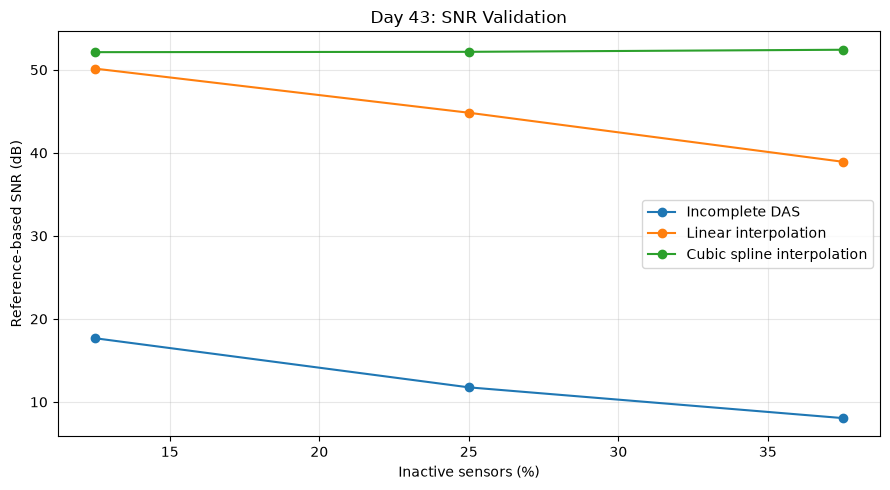


All validation tests passed.
Saved: ../outputs/day43_snr_validation.png
Saved: ../outputs/day43_snr_validation_results.json


In [1]:

import numpy as np
import json
import matplotlib.pyplot as plt
from pathlib import Path

# Project output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)


def calculate_snr(reference, estimate):
    """Calculate reference-based SNR in dB."""
    reference = np.asarray(reference, dtype=float)
    estimate = np.asarray(estimate, dtype=float)

    if reference.shape != estimate.shape:
        raise ValueError(
            "Reference and estimate must have the same shape."
        )

    signal_power = np.sum(reference ** 2)
    error_power = np.sum((reference - estimate) ** 2)

    if error_power == 0:
        return float("inf")

    if signal_power == 0:
        return float("-inf")

    return float(10 * np.log10(signal_power / error_power))


# ---------------------------------------
# Test 1: Identical images
# ---------------------------------------
reference = np.array([1.0, 2.0, 3.0, 4.0])

snr_perfect = calculate_snr(reference, reference.copy())

assert np.isinf(snr_perfect) and snr_perfect > 0
print("Test 1 passed: identical images produce infinite SNR.")


# ---------------------------------------
# Test 2: Increasing reconstruction error
# ---------------------------------------
estimate_small_error = reference + np.array(
    [0.01, -0.01, 0.01, -0.01]
)

estimate_large_error = reference + np.array(
    [0.5, -0.5, 0.5, -0.5]
)

snr_small_error = calculate_snr(
    reference, estimate_small_error
)

snr_large_error = calculate_snr(
    reference, estimate_large_error
)

assert snr_small_error > snr_large_error
print("Test 2 passed: larger error produces lower SNR.")
print(f"SNR with small error: {snr_small_error:.2f} dB")
print(f"SNR with large error: {snr_large_error:.2f} dB")


# ---------------------------------------
# Test 3: Load Day 42 results
# ---------------------------------------
results_path = output_dir / "day42_snr_robustness_results.json"

with open(results_path, "r", encoding="utf-8") as f:
    day42_results = json.load(f)

dropout_counts = sorted(
    [int(key) for key in day42_results.keys()]
)

incomplete_values = []
linear_values = []
spline_values = []

for count in dropout_counts:
    result = day42_results[str(count)]

    incomplete_values.append(result["snr_incomplete_db"])
    linear_values.append(result["snr_linear_db"])
    spline_values.append(result["snr_spline_db"])

    assert np.isfinite(result["snr_incomplete_db"])
    assert np.isfinite(result["snr_linear_db"])
    assert np.isfinite(result["snr_spline_db"])

print("Test 3 passed: Day 42 results loaded and values are finite.")


# ---------------------------------------
# Plot validation results
# ---------------------------------------
dropout_percentages = [
    day42_results[str(count)]["dropout_percentage"]
    for count in dropout_counts
]

plt.figure(figsize=(9, 5))

plt.plot(
    dropout_percentages,
    incomplete_values,
    marker="o",
    label="Incomplete DAS"
)
plt.plot(
    dropout_percentages,
    linear_values,
    marker="o",
    label="Linear interpolation"
)
plt.plot(
    dropout_percentages,
    spline_values,
    marker="o",
    label="Cubic spline interpolation"
)

plt.xlabel("Inactive sensors (%)")
plt.ylabel("Reference-based SNR (dB)")
plt.title("Day 43: SNR Validation")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "../outputs/day43_snr_validation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ---------------------------------------
# Save validation report
# ---------------------------------------
validation_report = {
    "day": 43,
    "metric": "Reference-based SNR",
    "test_identical_images": "passed",
    "test_increasing_error": "passed",
    "test_day42_results": "passed",
    "small_error_snr_db": snr_small_error,
    "large_error_snr_db": snr_large_error,
    "dropout_percentages": dropout_percentages,
    "snr_incomplete_db": incomplete_values,
    "snr_linear_db": linear_values,
    "snr_spline_db": spline_values,
    "reference_note": (
        "Full-array DAS is a computational reference, "
        "not independent physical ground truth."
    )
}

with open(
    output_dir / "day43_snr_validation_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        validation_report,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\nAll validation tests passed.")
print("Saved: ../outputs/day43_snr_validation.png")
print("Saved: ../outputs/day43_snr_validation_results.json")

